NOTEBOOK 14: FINAL INTERPRETABLE CHURN PREDICTION FRAMEWORK
Random State: 42
Test Size: 0.2
Final Decision Threshold: 0.21
False Negative Cost: 5
False Positive Cost: 1

Dataset Shape:
(10000, 45)

Columns:
['gender', 'age', 'country', 'city', 'customer_segment', 'tenure_months', 'signup_channel', 'contract_type', 'monthly_logins', 'weekly_active_days', 'avg_session_time', 'features_used', 'usage_growth_rate', 'last_login_days_ago', 'monthly_fee', 'total_revenue', 'payment_method', 'payment_failures', 'discount_applied', 'price_increase_last_3m', 'support_tickets', 'avg_resolution_time', 'complaint_type', 'csat_score', 'escalations', 'email_open_rate', 'marketing_click_rate', 'nps_score', 'survey_response', 'referral_count', 'churn', 'estimated_clv', 'engagement_score', 'support_burden', 'marketing_engagement', 'revenue_per_login', 'complaint_severity', 'activity_index', 'payment_risk', 'nps_scaled', 'csat_scaled', 'customer_satisfaction_index', 'inactivity_score', 'complaint_ratio', '

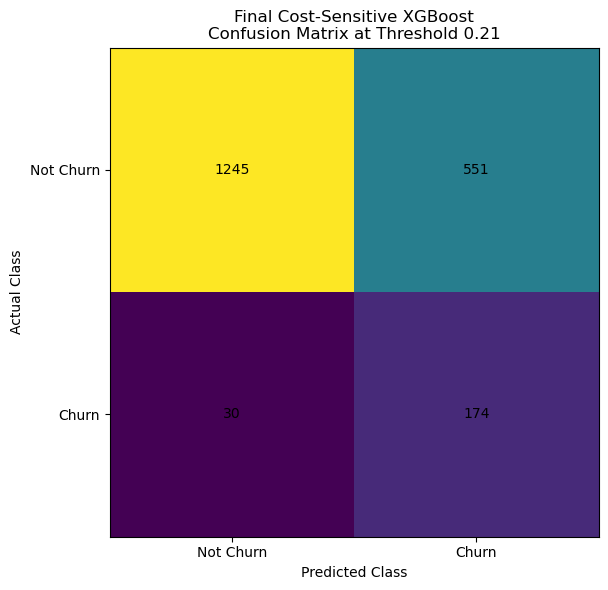


Risk Group Distribution:
risk_group
Low          762
Moderate     513
High         396
Very High    329
Name: count, dtype: int64

RISK GROUP VALIDATION
risk_group  customers  actual_churners  observed_churn_rate  mean_predicted_probability  predicted_churners
       Low        762               15             1.968504                    7.658888                   0
  Moderate        513               15             2.923977                   12.928460                   0
      High        396               81            20.454545                   32.183998                 396
 Very High        329               93            28.267477                   50.388336                 329


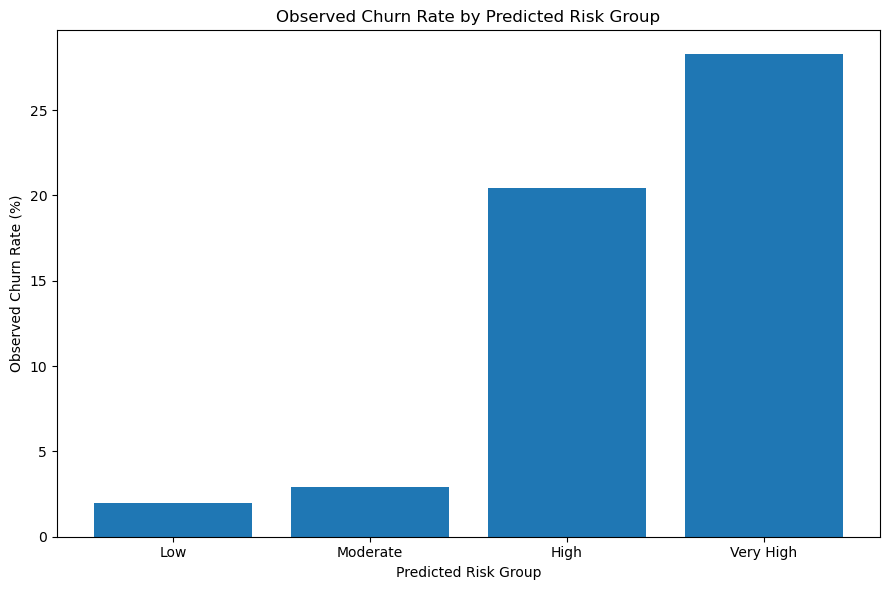


RISK DECILE ANALYSIS
 risk_decile  customers  actual_churners  observed_churn_rate  mean_predicted_probability  capture_rate     lift
           1        200               63                 31.5                   55.297775     30.882353 3.088235
           2        200               39                 19.5                   41.447414     19.117647 1.911765
           3        200               48                 24.0                   33.823025     23.529412 2.352941
           4        200               27                 13.5                   22.738951     13.235294 1.323529
           5        200                5                  2.5                   13.433762      2.450980 0.245098
           6        200                7                  3.5                   11.101147      3.431373 0.343137
           7        200                3                  1.5                    9.625852      1.470588 0.147059
           8        200                3                  1.5             

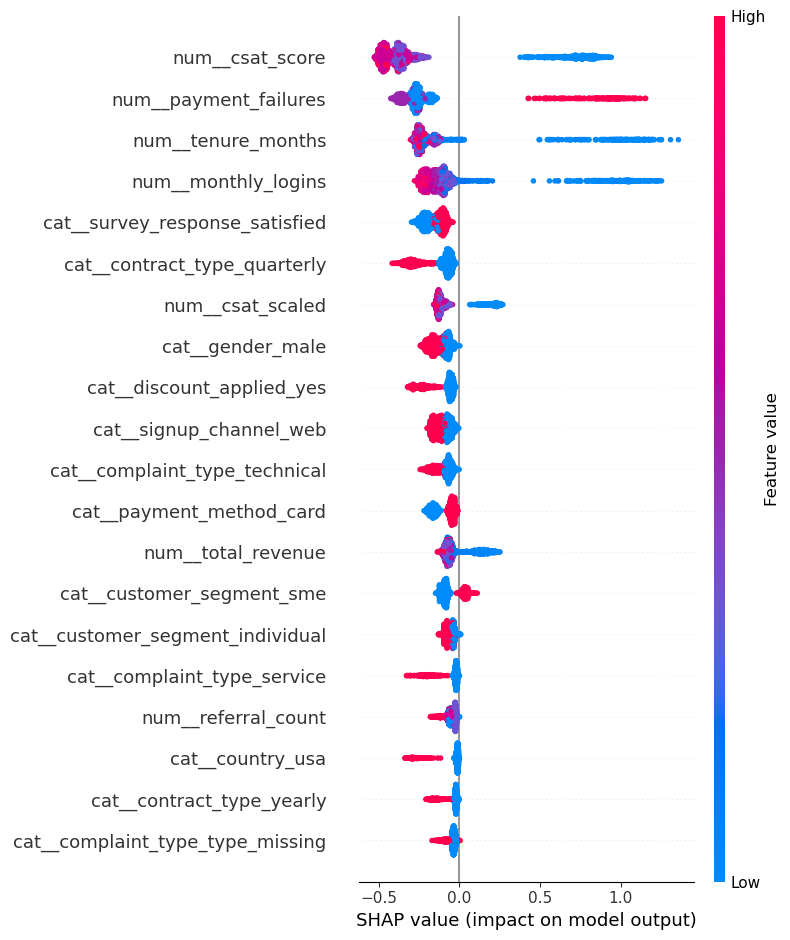

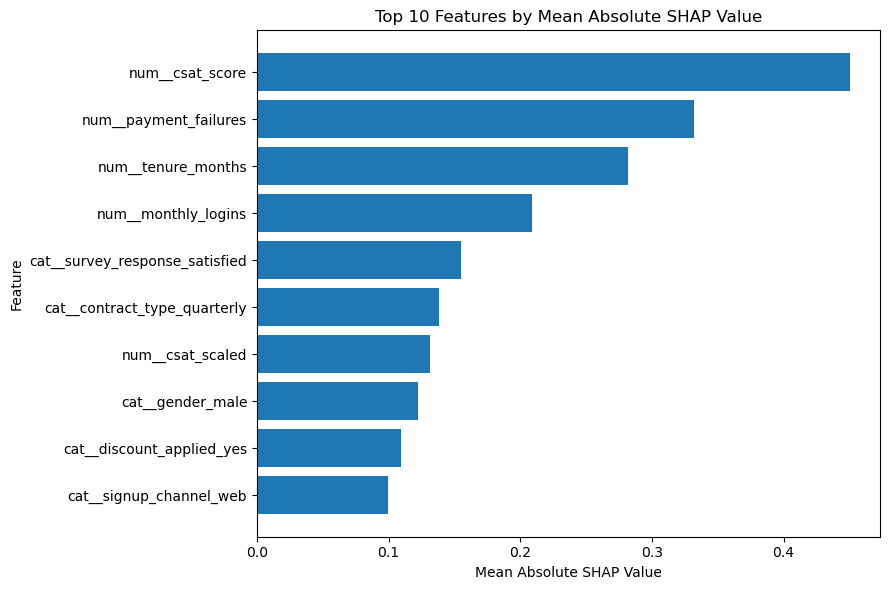

<Figure size 640x480 with 0 Axes>

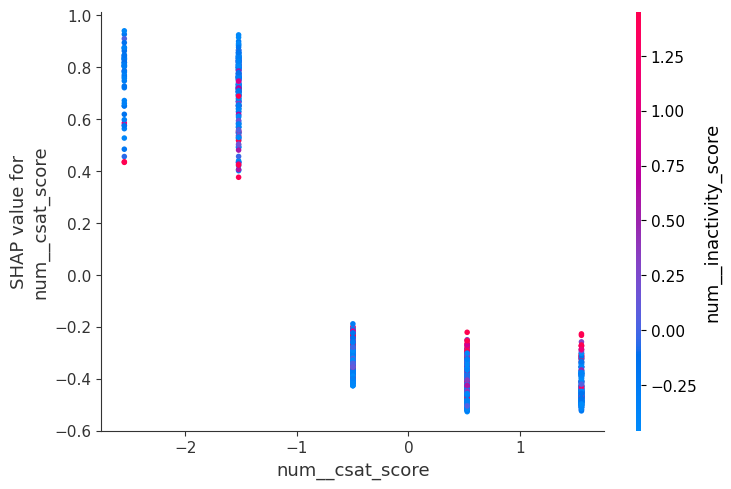

<Figure size 640x480 with 0 Axes>

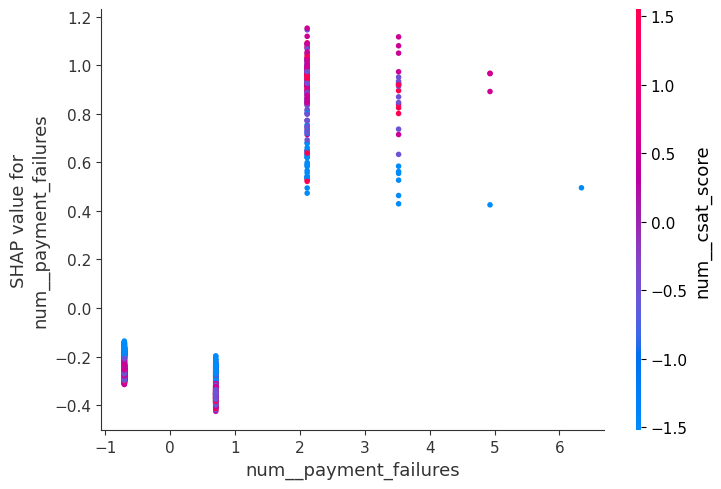

<Figure size 640x480 with 0 Axes>

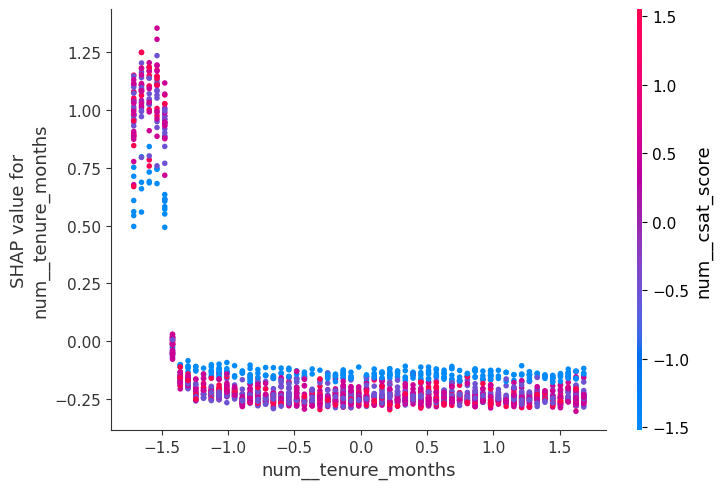


HIGHEST PREDICTED-PROBABILITY CUSTOMER
Test-set index: 7693
Predicted probability: 0.7627
Predicted class: 1
Actual churn: 0

Top SHAP Contributors:
                         feature  shap_value  absolute_shap
              num__tenure_months    0.887201       0.887201
             num__monthly_logins    0.745350       0.745350
                 num__csat_score   -0.250232       0.250232
           num__payment_failures   -0.222584       0.222584
              num__total_revenue    0.134158       0.134158
             num__referral_count   -0.115842       0.115842
         cat__signup_channel_web   -0.105693       0.105693
                cat__gender_male   -0.099000       0.099000
  cat__survey_response_satisfied   -0.078382       0.078382
                num__csat_scaled   -0.074573       0.074573
          num__revenue_per_login    0.070165       0.070165
   cat__complaint_type_technical   -0.065947       0.065947
cat__customer_segment_individual   -0.061492       0.061492
       cat

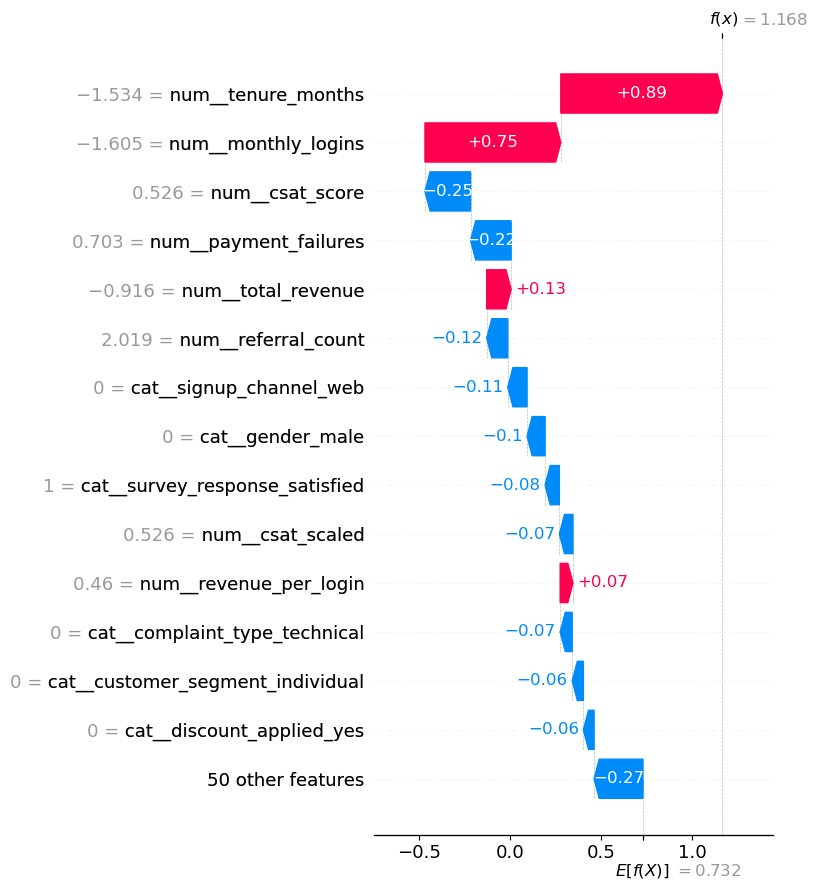


LOWEST PREDICTED-PROBABILITY CUSTOMER
Test-set index: 6360
Predicted probability: 0.0321
Predicted class: 0
Actual churn: 0


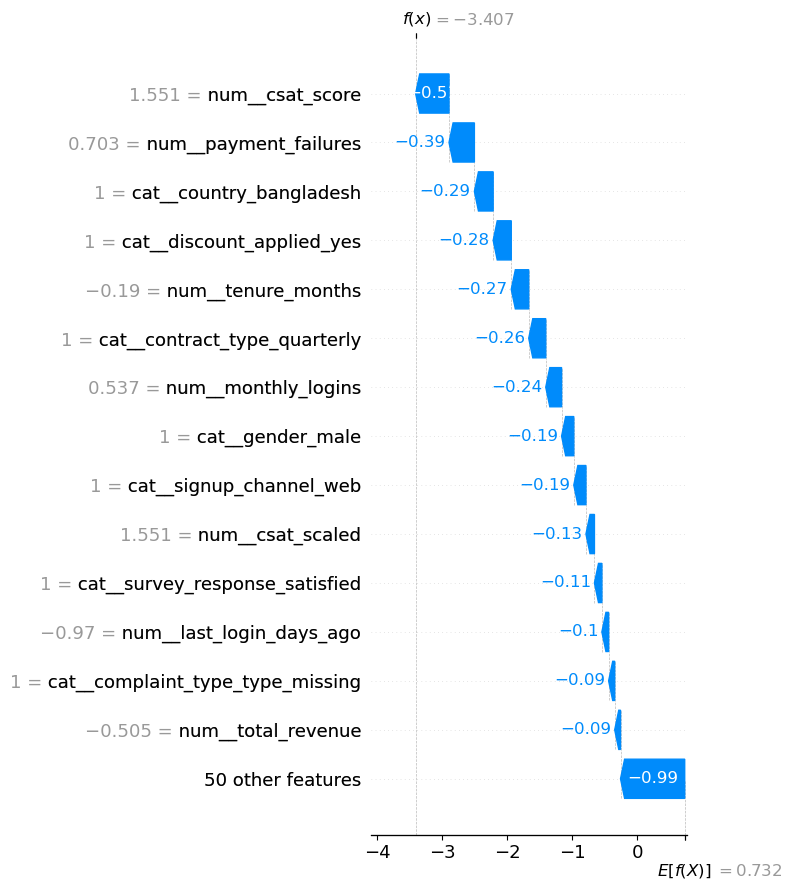


ORIGINAL FEATURE SHAP IMPORTANCE
original_feature  mean_absolute_shap
      csat_score            0.450743
payment_failures            0.331749
   tenure_months            0.281920
         country            0.212348
  monthly_logins            0.208815
  complaint_type            0.196820
 survey_response            0.188942
            city            0.185563
   contract_type            0.183637
customer_segment            0.135525
  signup_channel            0.133861
     csat_scaled            0.131429
          gender            0.122070
discount_applied            0.109214
  payment_method            0.106758

FINAL FRAMEWORK SUMMARY
           Component                                     Value
       Input Dataset Customer Churn Feature-Engineered Dataset
         Final Model                    Cost-Sensitive XGBoost
  Decision Threshold                                      0.21
            Accuracy                                    0.7095
           Precision              

In [ ]:

# Libraries

import os
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")



# Configuration

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Final threshold selected using training/CV information
FINAL_THRESHOLD = 0.21

# Hypothetical business-cost assumptions
FALSE_NEGATIVE_COST = 5
FALSE_POSITIVE_COST = 1

# Input dataset
DATA_PATH = "customer_churn_feature_engineered.csv"

# Final model
MODEL_PATH = (
    "cost_sensitive_model_results/"
    "Best_Cost_Sensitive_XGBoost.pkl"
)

# Output directory
OUTPUT_DIR = "final_interpretable_framework_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)


print("=" * 80)
print("NOTEBOOK 14: FINAL INTERPRETABLE CHURN PREDICTION FRAMEWORK")
print("=" * 80)

print(f"Random State: {RANDOM_STATE}")
print(f"Test Size: {TEST_SIZE}")
print(f"Final Decision Threshold: {FINAL_THRESHOLD}")
print(f"False Negative Cost: {FALSE_NEGATIVE_COST}")
print(f"False Positive Cost: {FALSE_POSITIVE_COST}")
print("=" * 80)



# Load Dataset

CustomerData_Df = pd.read_csv(DATA_PATH)

print("\nDataset Shape:")
print(CustomerData_Df.shape)

print("\nColumns:")
print(CustomerData_Df.columns.tolist())

print("\nMissing Values:")
print(CustomerData_Df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(CustomerData_Df.duplicated().sum())



# Dataset Validation


assert "churn" in CustomerData_Df.columns, \
    "Target column 'churn' was not found."

assert CustomerData_Df["churn"].isnull().sum() == 0, \
    "Missing target values detected."

assert CustomerData_Df.duplicated().sum() == 0, \
    "Duplicate rows detected."

print("\nDataset validation passed.")


# Define Features and Target


X = CustomerData_Df.drop(columns=["churn"]).copy()
y = CustomerData_Df["churn"].copy()

# Customer ID is an identifier and should not be used as a predictor
if "customer_id" in X.columns:
    X = X.drop(columns=["customer_id"])

print("\nFeature Matrix Shape:")
print(X.shape)

print("\nTarget Distribution:")
print(y.value_counts().sort_index())

print("\nTarget Distribution (%):")
print(
    (y.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)



# Recreate the Exact Train/Test Split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("\nTrain/Test Split:")
print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

print("\nTraining Target Distribution:")
print(y_train.value_counts().sort_index())

print("\nTest Target Distribution:")
print(y_test.value_counts().sort_index())



# Load Final Cost-Sensitive XGBoost Model

final_model = joblib.load(MODEL_PATH)

print("\nFinal Model Loaded:")
print(type(final_model))

print("\nPipeline Steps:")
print(final_model.named_steps)



test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

print("\nPrediction Summary:")
print(f"Minimum probability: {test_probabilities.min():.4f}")
print(f"Maximum probability: {test_probabilities.max():.4f}")
print(f"Mean probability: {test_probabilities.mean():.4f}")

print("\nPredicted Classes:")
print(
    pd.Series(test_predictions)
    .value_counts()
    .sort_index()
)



# Final Model Evaluation


tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions
).ravel()

accuracy = accuracy_score(y_test, test_predictions)
precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)
recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)
f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)
roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)
average_precision = average_precision_score(
    y_test,
    test_probabilities
)
balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_predictions
)

specificity = tn / (tn + fp)

business_cost = (
    fn * FALSE_NEGATIVE_COST
    + fp * FALSE_POSITIVE_COST
)

Final_Performance_Df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Balanced Accuracy",
        "Specificity",
        "True Positives",
        "False Positives",
        "False Negatives",
        "True Negatives",
        "Business Cost",
        "Decision Threshold"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        average_precision,
        balanced_accuracy,
        specificity,
        tp,
        fp,
        fn,
        tn,
        business_cost,
        FINAL_THRESHOLD
    ]
})

print("\n" + "=" * 80)
print("FINAL MODEL PERFORMANCE")
print("=" * 80)

print(Final_Performance_Df.to_string(index=False))

Final_Performance_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Framework_Model_Performance.csv"
    ),
    index=False
)



# Confusion Matrix

cm = np.array([
    [tn, fp],
    [fn, tp]
])

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title(
    f"Final Cost-Sensitive XGBoost\n"
    f"Confusion Matrix at Threshold {FINAL_THRESHOLD}"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Not Churn", "Churn"]
)

plt.yticks(
    [0, 1],
    ["Not Churn", "Churn"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Final_Framework_Confusion_Matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# Create Customer-Level Prediction Dataset


Framework_Test_Df = X_test.copy()

Framework_Test_Df["actual_churn"] = y_test.values
Framework_Test_Df["predicted_probability"] = test_probabilities
Framework_Test_Df["predicted_churn"] = test_predictions

Framework_Test_Df["decision_threshold"] = FINAL_THRESHOLD



# Risk Classification


def assign_risk_group(probability):

    if probability < 0.10:
        return "Low"
    
    elif probability < FINAL_THRESHOLD:
        return "Moderate"
    
    elif probability < 0.40:
        return "High"
    
    else:
        return "Very High"


Framework_Test_Df["risk_group"] = (
    Framework_Test_Df["predicted_probability"]
    .apply(assign_risk_group)
)


risk_order = [
    "Low",
    "Moderate",
    "High",
    "Very High"
]

Framework_Test_Df["risk_group"] = pd.Categorical(
    Framework_Test_Df["risk_group"],
    categories=risk_order,
    ordered=True
)

print("\nRisk Group Distribution:")

print(
    Framework_Test_Df["risk_group"]
    .value_counts()
    .sort_index()
)



# Risk Group Validation


Risk_Group_Df = (
    Framework_Test_Df
    .groupby(
        "risk_group",
        observed=False
    )
    .agg(
        customers=("actual_churn", "size"),
        actual_churners=("actual_churn", "sum"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        ),
        predicted_churners=("predicted_churn", "sum")
    )
    .reset_index()
)

Risk_Group_Df["observed_churn_rate"] = (
    Risk_Group_Df["observed_churn_rate"] * 100
)

Risk_Group_Df["mean_predicted_probability"] = (
    Risk_Group_Df["mean_predicted_probability"] * 100
)

print("\n" + "=" * 80)
print("RISK GROUP VALIDATION")
print("=" * 80)

print(Risk_Group_Df.to_string(index=False))

Risk_Group_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Risk_Group_Analysis.csv"
    ),
    index=False
)



# Risk Group Visualisation

plt.figure(figsize=(9, 6))

plt.bar(
    Risk_Group_Df["risk_group"].astype(str),
    Risk_Group_Df["observed_churn_rate"]
)

plt.title(
    "Observed Churn Rate by Predicted Risk Group"
)

plt.xlabel("Predicted Risk Group")
plt.ylabel("Observed Churn Rate (%)")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Final_Risk_Group_Churn_Rate.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Risk Decile Analysis


Decile_Df = Framework_Test_Df.copy()

Decile_Df["risk_decile"] = pd.qcut(
    Decile_Df["predicted_probability"],
    q=10,
    labels=False,
    duplicates="drop"
)

# Reverse ranking so 1 = highest predicted risk
Decile_Df["risk_decile"] = (
    Decile_Df["risk_decile"].max()
    - Decile_Df["risk_decile"]
    + 1
)

Total_Churners = Decile_Df["actual_churn"].sum()

Risk_Decile_Df = (
    Decile_Df
    .groupby("risk_decile")
    .agg(
        customers=("actual_churn", "size"),
        actual_churners=("actual_churn", "sum"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        )
    )
    .reset_index()
    .sort_values("risk_decile")
)

Risk_Decile_Df["capture_rate"] = (
    Risk_Decile_Df["actual_churners"]
    / Total_Churners
)

Overall_Churn_Rate = y_test.mean()

Risk_Decile_Df["lift"] = (
    Risk_Decile_Df["observed_churn_rate"]
    / Overall_Churn_Rate
)

Risk_Decile_Df["observed_churn_rate"] *= 100
Risk_Decile_Df["mean_predicted_probability"] *= 100
Risk_Decile_Df["capture_rate"] *= 100

print("\n" + "=" * 80)
print("RISK DECILE ANALYSIS")
print("=" * 80)

print(Risk_Decile_Df.to_string(index=False))

Risk_Decile_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Risk_Decile_Analysis.csv"
    ),
    index=False
)


# Retention Targeting Analysis

Ranking_Df = Framework_Test_Df.copy()

Ranking_Df = Ranking_Df.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)

target_percentages = [
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    80,
    90,
    100
]

Retention_Results = []

for percentage in target_percentages:

    n_target = int(
        len(Ranking_Df) * percentage / 100
    )

    Targeted_Df = Ranking_Df.iloc[:n_target]

    actual_churners_captured = (
        Targeted_Df["actual_churn"].sum()
    )

    precision_target = (
        actual_churners_captured / n_target
        if n_target > 0
        else 0
    )

    capture_rate = (
        actual_churners_captured / Total_Churners
    )

    lift = (
        precision_target / Overall_Churn_Rate
    )

    Retention_Results.append({
        "targeted_percentage": percentage,
        "customers_targeted": n_target,
        "actual_churners_captured": (
            actual_churners_captured
        ),
        "precision": precision_target,
        "capture_rate": capture_rate,
        "lift": lift
    })


Retention_Df = pd.DataFrame(Retention_Results)

Retention_Df["precision"] *= 100
Retention_Df["capture_rate"] *= 100

print("\n" + "=" * 80)
print("RETENTION TARGETING ANALYSIS")
print("=" * 80)

print(Retention_Df.to_string(index=False))

Retention_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Retention_Targeting_Analysis.csv"
    ),
    index=False
)



#  Top 10% Retention Targeting

Top10 = Ranking_Df.iloc[
    :int(len(Ranking_Df) * 0.10)
]

Top10_Captured = Top10["actual_churn"].sum()

Top10_Capture_Rate = (
    Top10_Captured / Total_Churners
)

Top10_Precision = (
    Top10_Captured / len(Top10)
)

Top10_Lift = (
    Top10_Precision / Overall_Churn_Rate
)

Top10_Summary = pd.DataFrame({
    "Metric": [
        "Customers Targeted",
        "Actual Churners Captured",
        "Precision",
        "Capture Rate",
        "Lift"
    ],
    "Value": [
        len(Top10),
        Top10_Captured,
        Top10_Precision,
        Top10_Capture_Rate,
        Top10_Lift
    ]
})

print("\n" + "=" * 80)
print("TOP 10% RETENTION TARGETING")
print("=" * 80)

print(Top10_Summary.to_string(index=False))

Top10_Summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Top10_Retention_Summary.csv"
    ),
    index=False
)


# Customer Value / CLV Integration


if "estimated_clv" in Framework_Test_Df.columns:

    training_clv_median = X_train[
        "estimated_clv"
    ].median()

    Framework_Test_Df["value_group"] = np.where(
        Framework_Test_Df["estimated_clv"]
        >= training_clv_median,
        "High Value",
        "Lower Value"
    )

    # Risk group based on final threshold
    high_risk_mask = (
        Framework_Test_Df["predicted_probability"]
        >= FINAL_THRESHOLD
    )

    high_value_mask = (
        Framework_Test_Df["estimated_clv"]
        >= training_clv_median
    )

    Framework_Test_Df["priority_group"] = np.select(
        [
            high_risk_mask & high_value_mask,
            high_risk_mask & ~high_value_mask,
            ~high_risk_mask & high_value_mask,
            ~high_risk_mask & ~high_value_mask
        ],
        [
            "Priority 1: High Risk / High Value",
            "Priority 2: High Risk / Lower Value",
            "Priority 3: Low Risk / High Value",
            "Priority 4: Low Risk / Lower Value"
        ],
        default="Unclassified"
    )

    Value_Risk_Df = (
        Framework_Test_Df
        .groupby("priority_group")
        .agg(
            customers=("actual_churn", "size"),
            actual_churners=("actual_churn", "sum"),
            observed_churn_rate=("actual_churn", "mean"),
            mean_predicted_probability=(
                "predicted_probability",
                "mean"
            ),
            mean_clv=("estimated_clv", "mean")
        )
        .reset_index()
    )

    Value_Risk_Df["observed_churn_rate"] *= 100
    Value_Risk_Df["mean_predicted_probability"] *= 100

    print("\n" + "=" * 80)
    print("CUSTOMER VALUE + CHURN RISK PRIORITISATION")
    print("=" * 80)

    print(
        f"Training-set CLV median: "
        f"{training_clv_median:.2f}"
    )

    print(
        Value_Risk_Df.to_string(index=False)
    )

    Value_Risk_Df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "Final_Customer_Value_Risk_Prioritisation.csv"
        ),
        index=False
    )

else:

    print(
        "\nEstimated CLV not available. "
        "Customer value prioritisation skipped."
    )



# Retention Action Priorities

def assign_retention_action(row):

    probability = row["predicted_probability"]

    if probability >= 0.40:
        return "Immediate Retention Review"

    elif probability >= FINAL_THRESHOLD:
        return "Proactive Retention Intervention"

    elif probability >= 0.10:
        return "Monitor Customer"

    else:
        return "Standard Engagement"


Framework_Test_Df["retention_action"] = (
    Framework_Test_Df
    .apply(assign_retention_action, axis=1)
)

Retention_Action_Df = (
    Framework_Test_Df
    .groupby("retention_action")
    .agg(
        customers=("actual_churn", "size"),
        actual_churners=("actual_churn", "sum"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        )
    )
    .reset_index()
)

Retention_Action_Df["observed_churn_rate"] *= 100
Retention_Action_Df["mean_predicted_probability"] *= 100

print("\n" + "=" * 80)
print("RETENTION ACTION PRIORITIES")
print("=" * 80)

print(
    Retention_Action_Df.to_string(index=False)
)

Retention_Action_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Retention_Action_Priorities.csv"
    ),
    index=False
)



# Error Analysis


Framework_Test_Df["prediction_error_type"] = np.select(
    [
        (Framework_Test_Df["actual_churn"] == 1)
        & (Framework_Test_Df["predicted_churn"] == 1),

        (Framework_Test_Df["actual_churn"] == 0)
        & (Framework_Test_Df["predicted_churn"] == 0),

        (Framework_Test_Df["actual_churn"] == 0)
        & (Framework_Test_Df["predicted_churn"] == 1),

        (Framework_Test_Df["actual_churn"] == 1)
        & (Framework_Test_Df["predicted_churn"] == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

Error_Summary_Df = (
    Framework_Test_Df["prediction_error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="customers")
)

print("\n" + "=" * 80)
print("PREDICTION ERROR ANALYSIS")
print("=" * 80)

print(Error_Summary_Df.to_string(index=False))

Error_Summary_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Prediction_Error_Summary.csv"
    ),
    index=False
)



#SHAP Explainability

print("\n" + "=" * 80)
print("SHAP EXPLAINABILITY")
print("=" * 80)

# Extract fitted preprocessing component
fitted_preprocessor = (
    final_model.named_steps["preprocessing"]
)

# Extract trained XGBoost model
xgb_model = (
    final_model.named_steps["model"]
)

# Transform test observations using preprocessing only
# IMPORTANT:
# No SMOTE is applied to the test data.
X_test_transformed = (
    fitted_preprocessor.transform(X_test)
)

# Convert sparse matrix to dense if necessary
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = (
        X_test_transformed.toarray()
    )

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print(
    f"SHAP input shape: "
    f"{X_test_shap.shape}"
)



#  Create SHAP Explainer

explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_test_shap
)

shap_values = np.asarray(shap_values)

print(
    f"SHAP value shape: "
    f"{shap_values.shape}"
)

assert shap_values.shape == X_test_shap.shape, \
    "SHAP dimensions do not match transformed features."



# Global SHAP Feature Importance


mean_abs_shap = np.abs(shap_values).mean(axis=0)

SHAP_Global_Df = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": mean_abs_shap
})

SHAP_Global_Df = (
    SHAP_Global_Df
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTop SHAP Features:")

print(
    SHAP_Global_Df.head(15)
    .to_string(index=False)
)

SHAP_Global_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_SHAP_Global_Feature_Importance.csv"
    ),
    index=False
)


# SHAP Summary Plot

plt.figure()

shap.summary_plot(
    shap_values,
    X_test_shap,
    show=False
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Final_SHAP_Summary_Plot.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# SHAP Top-10 Feature Plot

Top_SHAP = (
    SHAP_Global_Df
    .head(10)
    .sort_values(
        "mean_absolute_shap",
        ascending=True
    )
)

plt.figure(figsize=(9, 6))

plt.barh(
    Top_SHAP["feature"],
    Top_SHAP["mean_absolute_shap"]
)

plt.title(
    "Top 10 Features by Mean Absolute SHAP Value"
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Final_SHAP_Top10_Features.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# Dependence Plots for Top Three Features

Top_3_Features = (
    SHAP_Global_Df
    .head(3)["feature"]
    .tolist()
)

for i, feature in enumerate(
    Top_3_Features,
    start=1
):

    plt.figure()

    shap.dependence_plot(
        feature,
        shap_values,
        X_test_shap,
        show=False
    )

    plt.tight_layout()

    safe_feature_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
        .replace(":", "_")
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"Final_SHAP_Dependence_{i}_{safe_feature_name}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# Individual Customer SHAP Explanations

# Highest predicted probability customer
highest_risk_position = np.argmax(
    test_probabilities
)

highest_risk_index = X_test.index[
    highest_risk_position
]

highest_risk_probability = (
    test_probabilities[
        highest_risk_position
    ]
)

highest_risk_actual = y_test.loc[
    highest_risk_index
]

highest_risk_shap = shap_values[
    highest_risk_position
]

Highest_Risk_SHAP_Df = pd.DataFrame({
    "feature": feature_names,
    "shap_value": highest_risk_shap,
    "absolute_shap": np.abs(
        highest_risk_shap
    )
})

Highest_Risk_SHAP_Df = (
    Highest_Risk_SHAP_Df
    .sort_values(
        "absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("HIGHEST PREDICTED-PROBABILITY CUSTOMER")
print("=" * 80)

print(
    f"Test-set index: {highest_risk_index}"
)

print(
    f"Predicted probability: "
    f"{highest_risk_probability:.4f}"
)

print(
    f"Predicted class: "
    f"{int(highest_risk_probability >= FINAL_THRESHOLD)}"
)

print(
    f"Actual churn: "
    f"{highest_risk_actual}"
)

print("\nTop SHAP Contributors:")

print(
    Highest_Risk_SHAP_Df.head(15)
    .to_string(index=False)
)


Highest_Risk_SHAP_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Highest_Risk_Customer_SHAP_Explanation.csv"
    ),
    index=False
)


# Highest-Risk SHAP Waterfall

Highest_Risk_Explanation = shap.Explanation(
    values=highest_risk_shap,
    base_values=explainer.expected_value,
    data=X_test_shap.iloc[
        highest_risk_position
    ].values,
    feature_names=feature_names
)

plt.figure()

shap.plots.waterfall(
    Highest_Risk_Explanation,
    max_display=15,
    show=False
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Highest_Risk_Customer_SHAP_Waterfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Lowest Predicted-Probability Customer

lowest_risk_position = np.argmin(
    test_probabilities
)

lowest_risk_index = X_test.index[
    lowest_risk_position
]

lowest_risk_probability = (
    test_probabilities[
        lowest_risk_position
    ]
)

lowest_risk_actual = y_test.loc[
    lowest_risk_index
]

lowest_risk_shap = shap_values[
    lowest_risk_position
]

Lowest_Risk_SHAP_Df = pd.DataFrame({
    "feature": feature_names,
    "shap_value": lowest_risk_shap,
    "absolute_shap": np.abs(
        lowest_risk_shap
    )
})

Lowest_Risk_SHAP_Df = (
    Lowest_Risk_SHAP_Df
    .sort_values(
        "absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("LOWEST PREDICTED-PROBABILITY CUSTOMER")
print("=" * 80)

print(
    f"Test-set index: {lowest_risk_index}"
)

print(
    f"Predicted probability: "
    f"{lowest_risk_probability:.4f}"
)

print(
    f"Predicted class: "
    f"{int(lowest_risk_probability >= FINAL_THRESHOLD)}"
)

print(
    f"Actual churn: "
    f"{lowest_risk_actual}"
)

Lowest_Risk_SHAP_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Lowest_Risk_Customer_SHAP_Explanation.csv"
    ),
    index=False
)



# Lowest-Risk SHAP Waterfall

Lowest_Risk_Explanation = shap.Explanation(
    values=lowest_risk_shap,
    base_values=explainer.expected_value,
    data=X_test_shap.iloc[
        lowest_risk_position
    ].values,
    feature_names=feature_names
)

plt.figure()

shap.plots.waterfall(
    Lowest_Risk_Explanation,
    max_display=15,
    show=False
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Lowest_Risk_Customer_SHAP_Waterfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# SHAP Original Feature Aggregation


Original_Feature_SHAP = {}

for feature, shap_column in zip(
    feature_names,
    shap_values.T
):

    if "__" in feature:
        original_name = feature.split(
            "__",
            1
        )[1]
    else:
        original_name = feature

    
    if feature.startswith("cat__"):

        encoded_name = feature.replace(
            "cat__",
            ""
        )

        matched_original = None

        for original_column in X.columns:

            if encoded_name.startswith(
                original_column + "_"
            ):

                matched_original = (
                    original_column
                )

                break

        if matched_original is not None:
            original_name = matched_original

    if original_name not in Original_Feature_SHAP:
        Original_Feature_SHAP[
            original_name
        ] = 0

    Original_Feature_SHAP[
        original_name
    ] += np.mean(
        np.abs(shap_column)
    )


Original_SHAP_Df = pd.DataFrame(
    list(
        Original_Feature_SHAP.items()
    ),
    columns=[
        "original_feature",
        "mean_absolute_shap"
    ]
)

Original_SHAP_Df = (
    Original_SHAP_Df
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("ORIGINAL FEATURE SHAP IMPORTANCE")
print("=" * 80)

print(
    Original_SHAP_Df.head(15)
    .to_string(index=False)
)

Original_SHAP_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Original_Feature_SHAP_Importance.csv"
    ),
    index=False
)


# Customer-Level Framework Dataset

Framework_Test_Df["model_name"] = (
    "Cost-Sensitive XGBoost"
)

Framework_Test_Df["model_threshold"] = (
    FINAL_THRESHOLD
)

Framework_Test_Df["false_negative_cost"] = (
    FALSE_NEGATIVE_COST
)

Framework_Test_Df["false_positive_cost"] = (
    FALSE_POSITIVE_COST
)

Framework_Test_Df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Customer_Decision_Support_Dataset.csv"
    ),
    index=False
)



# Final Framework Summary

Final_Framework_Summary = pd.DataFrame({
    "Component": [
        "Input Dataset",
        "Final Model",
        "Decision Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Average Precision",
        "Balanced Accuracy",
        "Specificity",
        "True Positives",
        "False Positives",
        "False Negatives",
        "True Negatives",
        "Business Cost",
        "Top 10% Capture Rate",
        "Top 10% Precision",
        "Top 10% Lift",
        "SHAP Scope"
    ],
    "Value": [
        "Customer Churn Feature-Engineered Dataset",
        "Cost-Sensitive XGBoost",
        FINAL_THRESHOLD,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        average_precision,
        balanced_accuracy,
        specificity,
        tp,
        fp,
        fn,
        tn,
        business_cost,
        Top10_Capture_Rate,
        Top10_Precision,
        Top10_Lift,
        "Cost-Sensitive XGBoost component"
    ]
})

print("\n" + "=" * 80)
print("FINAL FRAMEWORK SUMMARY")
print("=" * 80)

print(
    Final_Framework_Summary.to_string(
        index=False
    )
)

Final_Framework_Summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Framework_Summary.csv"
    ),
    index=False
)



# Methodological Documentation

Methodological_Notes = pd.DataFrame({
    "Area": [
        "Final model",
        "Threshold selection",
        "Test-set evaluation",
        "SMOTE",
        "SHAP",
        "Hybrid architecture",
        "Business cost",
        "Risk terminology",
        "Customer action"
    ],

    "Method": [
        "Cost-Sensitive XGBoost selected as the primary business-oriented model.",
        
        "Threshold 0.21 was selected using training/CV information and "
        "then retained unchanged for the unseen test set.",
        
        "Final performance was evaluated on an unseen stratified 20% test set.",
        
        "SMOTE is contained inside the training pipeline and is not applied "
        "manually to test observations.",
        
        "SHAP explains the trained cost-sensitive XGBoost component.",
        
        "The weighted hybrid evaluated previously is a global 10% Logistic "
        "Regression + 90% XGBoost probability blend and is not an "
        "instance-dependent gating network.",
        
        "FN=5 and FP=1 are hypothetical methodological assumptions rather "
        "than observed company financial costs.",
        
        "Risk groups represent model-predicted probability categories and "
        "should not be interpreted as guaranteed customer outcomes.",
        
        "Retention actions are analytical decision-support suggestions and "
        "are not observed intervention outcomes."
    ]
})

Methodological_Notes.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_Framework_Methodological_Notes.csv"
    ),
    index=False
)


# Final Quality Checks

print("\n" + "=" * 80)
print("FINAL QUALITY CHECKS")
print("=" * 80)

assert len(X_train) == 8000
assert len(X_test) == 2000

assert y_train.sum() == 817
assert y_test.sum() == 204

assert 0 <= accuracy <= 1
assert 0 <= precision <= 1
assert 0 <= recall <= 1
assert 0 <= f1 <= 1
assert 0 <= roc_auc <= 1
assert 0 <= average_precision <= 1
assert 0 <= balanced_accuracy <= 1

assert (
    tp + fp + fn + tn
    == len(X_test)
)

assert (
    np.isclose(
        test_probabilities.mean(),
        Framework_Test_Df[
            "predicted_probability"
        ].mean()
    )
)

assert shap_values.shape == X_test_shap.shape

print("✓ Dataset shape validated")
print("✓ Train/test split reproduced")
print("✓ Target distribution validated")
print("✓ Final model loaded successfully")
print("✓ Threshold fixed at 0.21")
print("✓ SMOTE not applied to test data")
print("✓ Prediction probabilities validated")
print("✓ Final performance metrics validated")
print("✓ Risk classification validated")
print("✓ Risk decile analysis validated")
print("✓ Retention targeting validated")
print("✓ Customer value prioritisation validated")
print("✓ SHAP dimensions validated")
print("✓ SHAP feature importance generated")
print("✓ Individual SHAP explanations generated")
print("✓ Customer decision-support dataset generated")

print("\nAll Notebook 14 quality checks passed.")



# Final Analytical Interpretation

print("\n" + "=" * 80)
print("NOTEBOOK 14 COMPLETE")
print("=" * 80)

print("""
FINAL INTERPRETABLE CHURN PREDICTION FRAMEWORK
-----------------------------------------------

The final framework integrates:

1. Feature-engineered customer data
2. Cost-sensitive XGBoost prediction
3. A pre-selected decision threshold of 0.21
4. Customer-level churn probability estimation
5. Risk-group classification
6. Risk-decile ranking
7. Retention targeting analysis
8. Customer-value prioritisation
9. SHAP-based model explanation
10. Individual customer-level explanations

The framework is intended as a decision-support approach rather than
a guarantee of individual customer behaviour.

The final model identifies customers according to predicted churn
probability and supports prioritisation of retention resources.

SHAP explanations describe the contribution of input features to the
cost-sensitive XGBoost model predictions. They should not be interpreted
as causal relationships.

The weighted Logistic Regression + XGBoost hybrid remains a comparative
model from the previous experiments and is not represented here as an
instance-dependent gating architecture.
""")


# Saved Outputs

print("\nSaved Notebook 14 outputs:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    print(f" - {filename}")